# Legislator Stance Volume by Original Privacy Topic

| Item | Description |
|---|---|
| Goal | Compare concern and support for the five original topics in the privacy group, using the same figure style and speech-turn counting rule as T2.4.1. No topic modeling or re-clustering. |
| Input | `topic_groups.parquet` from T2.1.5; `privacy_and_digital_consumer_protection_stance_turns.csv` from T2.4.3 in the T2.4 Processed folder defines the existing sample; the upstream `track2_assigned.parquet` identifies each record's topic and stance. |
| Output | `fig_privacy_topic_stance_volume.png/.svg/.pdf` in the notebook's `R - Results` figure folder and `privacy_topic_stance_turn_counts.csv` in the T2.4 Interim folder. |
| Sample | House Science and Senate Commerce hearings held in 1999–2025, restricted to the previously exported privacy-group legislator turns. |
| Counting rule | Count each turn once per original topic and stance. A mixed-stance turn enters both bars but only once in its topic's total. A turn mentioning multiple topics can enter several rows. |
| Variables | • `topic_id`, `topic_label`: original codebook topic identifier and label, unchanged.<br>• `n_hearings`: distinct hearings with stance on the topic.<br>• `stance_turns`: distinct legislator speech turns with either stance; the sorting variable.<br>• `concern_turns`, `support_turns`: distinct speech turns expressing each stance.<br>• `both_stance_turns`: turns counted in both bars. |

**Flow:** select the five original topics → count speech turns → plot concern and support.
| Run | Made 2026-10-23 on the stored T2 outputs. Run again on 2026-10-31 after the inputs moved to the scratch root and the outputs to `R - Results`. No model call. |


## Step 1. Import packages

Use the same plotting tools as T2.4.1. Wrap long topic labels without changing their wording.

In [1]:
import textwrap
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.transforms import blended_transform_factory
from IPython.display import Image, Markdown, display

## Step 2. Define file locations

Read the existing sample and upstream topic assignments. Save only the new topic-level counts and figure in `output/T2.4.4/`.

In [2]:
PROJECT_FOLDER = Path.cwd().resolve().parents[1]  # <section>/<subfolder>/ sits two levels below the clone
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")  # the one line to change on another machine
NOTEBOOK_SUBFOLDER = Path("T2 - Topic Extraction and Stance Analysis/T2.4 - Stance by Topic over Time")
NOTEBOOK_NAME = "T2.4.4 - Privacy Topic Stance Volume"  # the notebook filename without .ipynb
INTERIM_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Interim"
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
T21_PROCESSED = SCRATCH_FOLDER / "T2 - Topic Extraction and Stance Analysis/T2.1 - Track 1 - Topic Extraction based on Hearing Summaries" / "Processed"
T22_PROCESSED = SCRATCH_FOLDER / "T2 - Topic Extraction and Stance Analysis/T2.2 - Track 2 - Legislator Stance Extraction" / "Processed"
D14_PROCESSED = SCRATCH_FOLDER / "D1 - Data Collection and Processing/D1.4 - SST Sample Construction" / "Processed"
FIGURE_FOLDER = PROJECT_FOLDER / "R - Results/figures" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
TABLE_FOLDER = PROJECT_FOLDER / "R - Results/tables" / NOTEBOOK_SUBFOLDER / NOTEBOOK_NAME
GROUPS_FILE = T21_PROCESSED / "topic_groups.parquet"
RECORDS_FILE = T22_PROCESSED / "track2_assigned.parquet"
TURNS_FILE = T22_PROCESSED / "member_turns.parquet"
HEARINGS_FILE = D14_PROCESSED / "hearings_sst.parquet"
SAMPLE_FILE = PROCESSED_FOLDER / "privacy_and_digital_consumer_protection_stance_turns.csv"  # written by T2.4.3
for folder in (INTERIM_FOLDER, PROCESSED_FOLDER, FIGURE_FOLDER):
    folder.mkdir(parents=True, exist_ok=True)

TARGET_GROUP = "Privacy and digital consumer protection"
EXPECTED_TOPIC_LABELS = [
    "Consumer privacy and anti-spam legislation",
    "Digital identity verification and protection",
    "consumer data privacy legislation",
    "Children's online privacy and safety legislation",
    "Online advertising and consumer choice policies",
]
YEAR_MIN = 1999
YEAR_MAX = 2025
TURN_KEYS = ["packageId", "turn_idx"]


## Step 3. Apply the figure style

Match T2.4.1: one 9-by-6-inch panel, concern in red, support in blue, bold column headings, and captions outside the exported image.

In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3
EXPORT_DPI = 300
BOLD_TEXT = {"fontweight": "bold", "fontfamily": "DejaVu Serif"}

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 9
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK

## Step 4. Select the five original topics

Use the approved mapping and preserve its original labels. Check that these are exactly the five requested topics.

In [4]:
topic_groups = pd.read_parquet(GROUPS_FILE, columns=["group", "label", "topic_id"])
assert topic_groups["topic_id"].is_unique
selected_topics = topic_groups.loc[topic_groups["group"].eq(TARGET_GROUP), ["topic_id", "label"]]
selected_topics = selected_topics.rename(columns={"label": "topic_label"})
assert len(selected_topics) == len(EXPECTED_TOPIC_LABELS)
assert set(selected_topics["topic_label"]) == set(EXPECTED_TOPIC_LABELS)
print(f"Original topics: {len(selected_topics)}")
display(selected_topics)

Original topics: 5


,topic_id,topic_label
91,65,Consumer privacy and anti-spam legislation
92,67,Digital identity verification and protection
93,68,consumer data privacy legislation
94,92,Children's online privacy and safety legislation
95,93,Online advertising and consumer choice policies


## Step 5. Read the existing privacy-group sample

Keep the same legislator turns and hearing-year window as the earlier privacy figures. The CSV's topic list does not identify each topic's stance, so the next step uses the original stance records.

In [5]:
sample_columns = TURN_KEYS + ["hearing_year", "n_stance_records", "has_concern", "has_support"]
sample_turns = pd.read_csv(SAMPLE_FILE, usecols=sample_columns)
assert not sample_turns.duplicated(TURN_KEYS).any()
assert sample_turns["hearing_year"].between(YEAR_MIN, YEAR_MAX).all()
assert sample_turns["n_stance_records"].gt(0).all()
print(f"Sample: {len(sample_turns):,} legislator turns in {sample_turns['packageId'].nunique():,} hearings.")
display(sample_turns.head(3))

Sample: 1,086 legislator turns in 551 hearings.


,packageId,hearing_year,turn_idx,has_concern,has_support,n_stance_records
0,CHRG-106shrg69592,1999,17,True,False,1
1,CHRG-106shrg69985,1999,4,False,True,3
2,CHRG-106shrg69984,1999,1,False,True,2


## Step 6. Recover topic-specific stance records

Match upstream records to the existing sample and attach the original topic labels. Check that every sampled turn retains its original number of stance records.

In [6]:
records = pd.read_parquet(
    RECORDS_FILE,
    columns=TURN_KEYS + ["record_idx", "bioGuideId", "topic_id", "stance"],
    filters=[("topic_id", "in", selected_topics["topic_id"].tolist())],
)
sample_records = records.merge(sample_turns[TURN_KEYS], on=TURN_KEYS, how="inner", validate="many_to_one")
sample_records = sample_records.merge(selected_topics, on="topic_id", how="left", validate="many_to_one")
assert sample_records.notna().all().all()
assert sample_records["stance"].isin(["concern", "support"]).all()
assert not sample_records.duplicated(TURN_KEYS + ["record_idx"]).any()
assert sample_records.groupby(TURN_KEYS)["bioGuideId"].nunique().eq(1).all()
pd.testing.assert_series_equal(
    sample_records.groupby(TURN_KEYS).size().sort_index(),
    sample_turns.set_index(TURN_KEYS)["n_stance_records"].sort_index(),
    check_names=False,
)
print(f"Matched stance records: {len(sample_records):,}")
display(sample_records[TURN_KEYS + ["topic_label", "stance"]].head(3))

Matched stance records: 1,654


,packageId,turn_idx,topic_label,stance
0,CHRG-106shrg69984,4,consumer data privacy legislation,support
1,CHRG-106shrg69984,4,Consumer privacy and anti-spam legislation,concern
2,CHRG-106shrg69984,4,Consumer privacy and anti-spam legislation,support


## Step 7. Count and rank the original topics

Deduplicate within topic, turn, and stance—not across topics. Sort by distinct stance-bearing turns, largest first, with the topic label breaking ties. Retain all five topics even if a count is zero.

In [7]:
topic_turn_keys = ["topic_id"] + TURN_KEYS
topic_turn_stances = sample_records.drop_duplicates(topic_turn_keys + ["stance"])
unique_topic_turns = topic_turn_stances.drop_duplicates(topic_turn_keys)
topic_counts = topic_turn_stances.groupby(["topic_id", "stance"]).size().unstack(fill_value=0)
topic_counts = topic_counts.reindex(
    index=selected_topics["topic_id"], columns=["concern", "support"], fill_value=0,
)
topic_counts = topic_counts.rename(columns={"concern": "concern_turns", "support": "support_turns"})
topic_counts.columns.name = None
turn_totals = unique_topic_turns.groupby("topic_id").size()
hearing_totals = unique_topic_turns.groupby("topic_id")["packageId"].nunique()
topic_counts["stance_turns"] = turn_totals.reindex(topic_counts.index, fill_value=0)
topic_counts["n_hearings"] = hearing_totals.reindex(topic_counts.index, fill_value=0)
topic_counts["both_stance_turns"] = (
    topic_counts["concern_turns"] + topic_counts["support_turns"] - topic_counts["stance_turns"]
)
topic_counts = topic_counts.reset_index().merge(selected_topics, on="topic_id", validate="one_to_one")
topic_counts = topic_counts.sort_values(["stance_turns", "topic_label"], ascending=[False, True])
topic_counts = topic_counts.reset_index(drop=True)
topic_counts = topic_counts[[
    "topic_id", "topic_label", "n_hearings", "stance_turns",
    "concern_turns", "support_turns", "both_stance_turns",
]]
assert len(topic_counts) == len(selected_topics)
assert topic_counts["stance_turns"].is_monotonic_decreasing
assert topic_counts["n_hearings"].le(topic_counts["stance_turns"]).all()
assert topic_counts["stance_turns"].sum() == len(unique_topic_turns)
assert topic_counts[["concern_turns", "support_turns"]].to_numpy().sum() == len(topic_turn_stances)
assert topic_counts["both_stance_turns"].ge(0).all()
assert topic_counts["both_stance_turns"].le(topic_counts[["concern_turns", "support_turns"]].min(axis=1)).all()
for stance in ["concern", "support"]:
    distinct_turns = sample_records.loc[sample_records["stance"].eq(stance)].drop_duplicates(TURN_KEYS)
    assert len(distinct_turns) == sample_turns[f"has_{stance}"].sum()
display(topic_counts)

,topic_id,topic_label,n_hearings,stance_turns,concern_turns,support_turns,both_stance_turns
0,65,Consumer privacy and anti-spam legislation,299,433,296,155,18
1,93,Online advertising and consumer choice policies,233,367,259,119,11
2,68,consumer data privacy legislation,119,243,117,146,20
3,67,Digital identity verification and protection,81,96,56,48,8
4,92,Children's online privacy and safety legislation,42,92,52,49,9


## Step 8. Save the figure data

Save the topic-level counts, including mixed-stance overlap, without changing earlier CSVs.

In [8]:
counts_file = INTERIM_FOLDER / "privacy_topic_stance_turn_counts.csv"
topic_counts.to_csv(counts_file, index=False)
print(f"Saved: {counts_file}")

Saved: /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T2 - Topic Extraction and Stance Analysis/T2.4 - Stance by Topic over Time/Interim/privacy_topic_stance_turn_counts.csv


## Step 9. Plot concern and support by original topic

Match Figure 1 in T2.4.1: original topic, hearing count, and stance-turn count appear to the left of the bars. Use the shared heading "Topics under Privacy Group" and capitalize the first letter of every displayed label without changing the source labels. Keep the largest topic at the top. Counts are speech turns, not stance records; no model-based topics or sponsor shares are included.

**Figure 1. Concern and Support by Topics under Privacy Group**

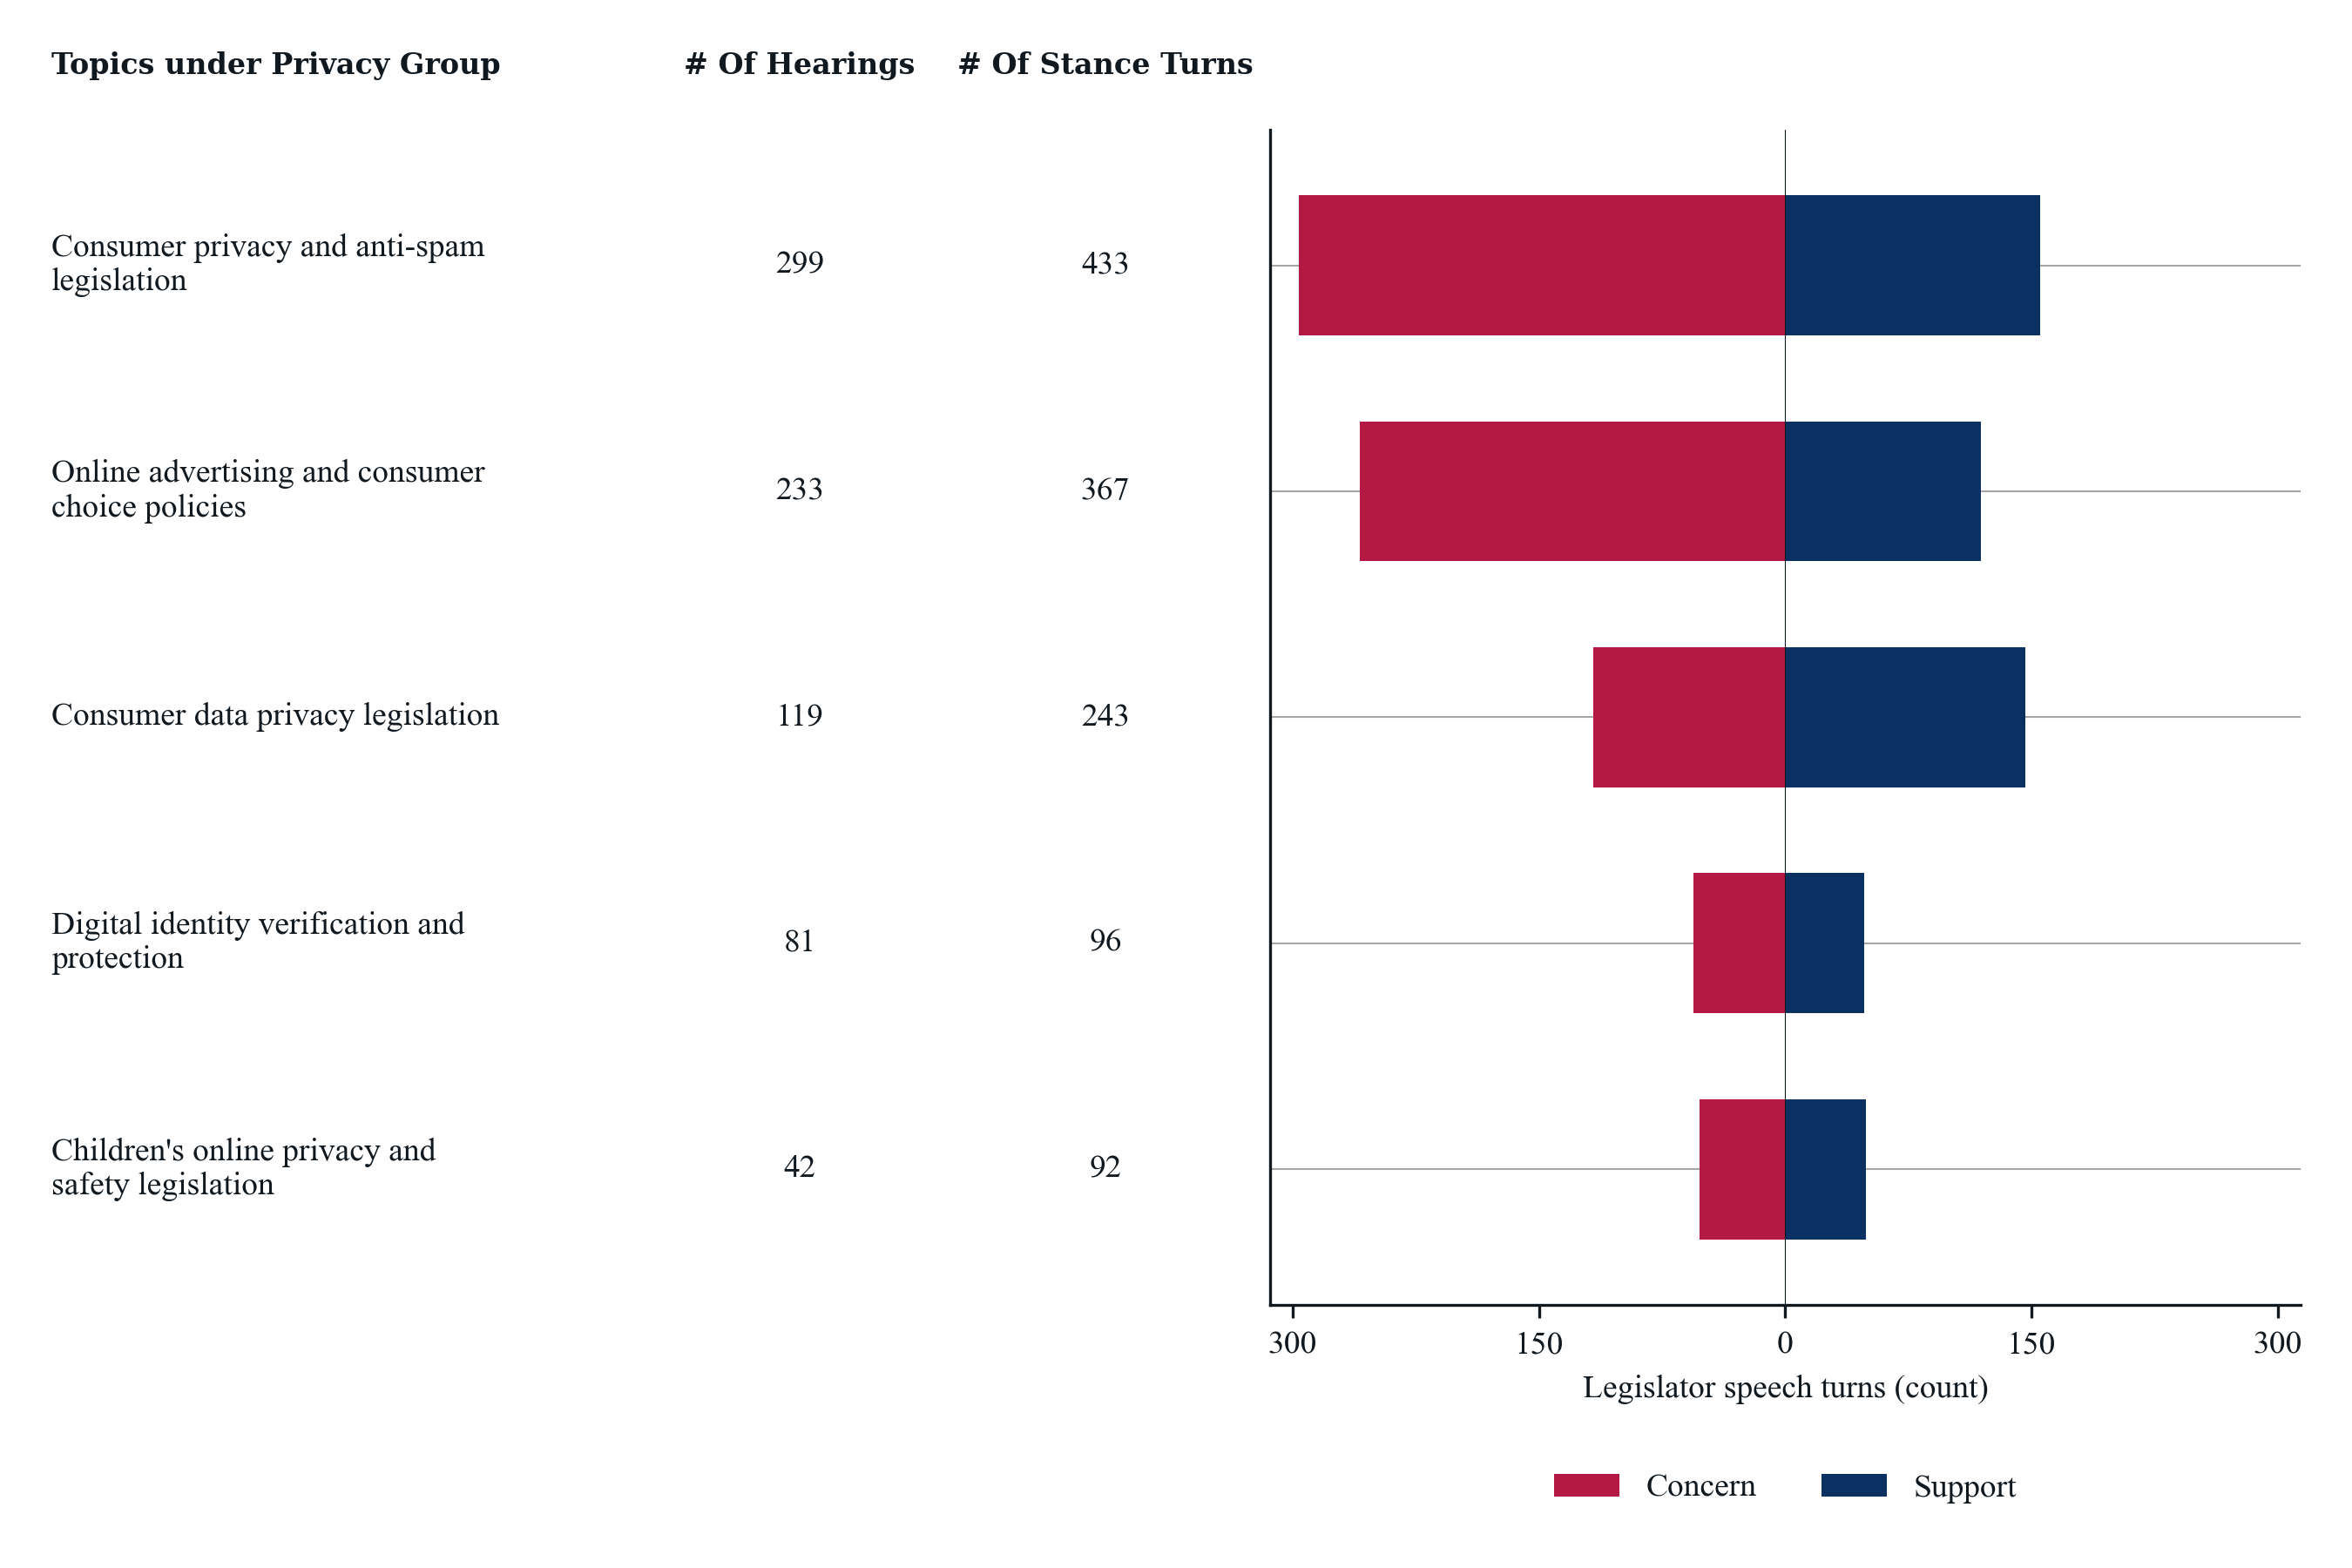

*Notes*: Sample: 551 House Science and Senate Commerce hearings, 1999–2025; 1,086 legislator speech turns in the privacy group. Counts are distinct hearings and stance-bearing turns per original topic. Concern: worry, criticism, objection, or calls for restriction, delay, or scrutiny. Support: endorsement, advocacy, or calls for adoption, funding, or expansion. Mixed-stance turns enter both bars but count once in totals; multi-topic turns can enter several rows.

*Source*: Extracted legislator stances and original topic labels.

saved fig_privacy_topic_stance_volume.png/.svg/.pdf


In [9]:
figure_name = "fig_privacy_topic_stance_volume"
figure_title = "Figure 1. Concern and Support by Topics under Privacy Group"
figure, axis = plt.subplots()
positions = range(len(topic_counts))
bar_height = 0.62
topic_column = MARGIN_INCHES / FIGURE_WIDTH
hearing_column = 0.34
turn_column = 0.47
plot_left = 0.54
plot_right = 1 - MARGIN_INCHES / FIGURE_WIDTH
header_top = 1 - MARGIN_INCHES / FIGURE_HEIGHT
figure.subplots_adjust(left=plot_left, right=plot_right, top=header_top - 0.05, bottom=0.2)

axis.barh(
    positions, -topic_counts["concern_turns"], height=bar_height, color=RED, label="Concern"
)
axis.barh(
    positions, topic_counts["support_turns"], height=bar_height, color=BLUE, label="Support"
)
axis.axvline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH)
axis.set_yticks(positions)
axis.set_ylim(len(topic_counts) - 0.4, -0.6)
axis.set_xlabel("Legislator speech turns (count)")
axis.tick_params(axis="y", left=False, labelleft=False)
axis.spines[["top", "right"]].set_visible(False)

row_transform = blended_transform_factory(figure.transFigure, axis.transData)
for position, row in enumerate(topic_counts.itertuples(index=False)):
    display_label = row.topic_label[:1].upper() + row.topic_label[1:]
    axis.text(
        topic_column, position, textwrap.fill(display_label, width=35), transform=row_transform,
        ha="left", va="center", fontsize=9, clip_on=False,
    )
    axis.text(
        hearing_column, position, f"{row.n_hearings:,}", transform=row_transform,
        ha="center", va="center", fontsize=9, clip_on=False,
    )
    axis.text(
        turn_column, position, f"{row.stance_turns:,}", transform=row_transform,
        ha="center", va="center", fontsize=9, clip_on=False,
    )

figure.text(
    topic_column, header_top, "Topics under Privacy Group", ha="left", va="top",
    fontsize=8, **BOLD_TEXT,
)
figure.text(
    hearing_column, header_top, "# Of Hearings", ha="center", va="top",
    fontsize=8, **BOLD_TEXT,
)
figure.text(
    turn_column, header_top, "# Of Stance Turns", ha="center", va="top",
    fontsize=8, **BOLD_TEXT,
)

maximum_count = topic_counts[["concern_turns", "support_turns"]].to_numpy().max()
axis_limit = max(1, maximum_count) * 1.06
axis.set_xlim(-axis_limit, axis_limit)
tick_positions = MaxNLocator(nbins=6, integer=True).tick_values(-axis_limit, axis_limit)
tick_positions = tick_positions[abs(tick_positions) <= axis_limit]
axis.set_xticks(tick_positions, labels=[f"{abs(int(value)):,}" for value in tick_positions])

legend = figure.legend(
    loc="lower center",
    bbox_to_anchor=((plot_left + plot_right) / 2, MARGIN_INCHES / FIGURE_HEIGHT),
    bbox_transform=figure.transFigure, ncol=2, frameon=False, borderaxespad=0,
)
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
legend_top = legend.get_window_extent(renderer).y1
label_bottom = axis.xaxis.label.get_window_extent(renderer).y0
bottom_shift = (legend_top + MARGIN_INCHES * figure.dpi - label_bottom) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)

for extension in ["png", "svg", "pdf"]:
    figure.savefig(FIGURE_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)

figure_notes = (
    f"Sample: {sample_turns['packageId'].nunique():,} House Science and Senate Commerce hearings, "
    f"{YEAR_MIN}–{YEAR_MAX}; {len(sample_turns):,} legislator speech turns in the privacy group. "
    "Counts are distinct hearings and stance-bearing turns per original topic. "
    "Concern: worry, criticism, objection, or calls for restriction, delay, or scrutiny. "
    "Support: endorsement, advocacy, or calls for adoption, funding, or expansion. "
    "Mixed-stance turns enter both bars but count once in totals; multi-topic turns can enter several rows."
)
figure_source = "Extracted legislator stances and original topic labels."
display(Markdown(f"**{figure_title}**"))
display(Image(filename=str(FIGURE_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {figure_notes}\n\n*Source*: {figure_source}"))
print(f"saved {figure_name}.png/.svg/.pdf")